### Load dữ liệu

In [9]:
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download(
    "msambare/fer2013"
)

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Admin\.cache\kagglehub\datasets\msambare\fer2013\versions\1


In [10]:
print(os.listdir(path))


['test', 'train']


In [11]:
train_path = os.path.join(
    path,
    "train"
)

test_path = os.path.join(
    path,
    "test"
)

print("Train path:", train_path)
print("Test path:", test_path)

print("\nTrain classes:")
print(os.listdir(train_path))

print("\nTest classes:")
print(os.listdir(test_path))

Train path: C:\Users\Admin\.cache\kagglehub\datasets\msambare\fer2013\versions\1\train
Test path: C:\Users\Admin\.cache\kagglehub\datasets\msambare\fer2013\versions\1\test

Train classes:
['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Test classes:
['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [14]:
from collections import Counter
import glob as _glob

def count_images(folder):

    counts = {}

    for class_name in os.listdir(folder):

        class_path = os.path.join(
            folder,
            class_name
        )

        if not os.path.isdir(class_path):
            continue

        image_files = []

        for ext in [
            "*.jpg",
            "*.jpeg",
            "*.png",
            "*.JPG",
            "*.JPEG",
            "*.PNG"
        ]:

            image_files.extend(
                _glob.glob(
                    os.path.join(
                        class_path,
                        ext
                    )
                )
            )

        counts[class_name] = len(
            image_files
        )

    return counts

In [15]:
train_counts = count_images(
    train_path
)

test_counts = count_images(
    test_path
)

print("TRAIN")
for cls, n in train_counts.items():
    print(
        f"{cls:<10}: {n:,}"
    )

print("\nTEST")
for cls, n in test_counts.items():
    print(
        f"{cls:<10}: {n:,}"
    )

TRAIN
angry     : 7,990
disgust   : 872
fear      : 8,194
happy     : 14,430
neutral   : 9,930
sad       : 9,660
surprise  : 6,342

TEST
angry     : 1,916
disgust   : 222
fear      : 2,048
happy     : 3,548
neutral   : 2,466
sad       : 2,494
surprise  : 1,662


Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.


In [ ]:
# Giữ ảnh ở dạng grayscale cho augmentation, convert RGB khi chuẩn bị cho MobileNet
# (Xóa bỏ bước grayscale_to_rgb ở đây để tránh lỗi lặp)

# Không cần convert to RGB ở đây nữa
# train_ds = train_ds.map(grayscale_to_rgb, num_parallel_calls=tf.data.AUTOTUNE)
# val_ds = val_ds.map(grayscale_to_rgb, num_parallel_calls=tf.data.AUTOTUNE)

In [ ]:
import tensorflow as tf
IMG_SIZE = (96, 96)
BATCH_SIZE = 64
NUM_CLASSES = 7

# ==========================================
# 2. LOAD DATASET (48x48x1)
# ==========================================
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds_raw.class_names
disgust_index = class_names.index("disgust") if "disgust" in class_names else 1

### Data preprocessing



In [ ]:
disgust_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.12),
    tf.keras.layers.RandomContrast(0.20),
    tf.keras.layers.RandomTranslation(0.10, 0.10)
])

normal_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
])

In [43]:
def class_specific_augmentation(image, label):

    class_id = tf.argmax(label, axis=-1)

    image = tf.cond(
        tf.equal(class_id, 1),   # 1 = disgust
        lambda: disgust_augmentation(image, training=True),
        lambda: normal_augmentation(image, training=True)
    )

    return image, label

In [44]:
train_ds = train_ds.unbatch()

train_ds = train_ds.map(
    class_specific_augmentation,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(
    BATCH_SIZE
)

train_ds = train_ds.prefetch(
    tf.data.AUTOTUNE
)

### Xây mô hình MobileNETV2

In [45]:
def prepare_for_mobilenet(image, label):
    # Chuyển đổi grayscale (1 kênh) thành RGB (3 kênh)
    image = tf.image.grayscale_to_rgb(image)
    
    # Resize ảnh để phù hợp với MobileNetV2
    image = tf.image.resize(image, (96, 96))
    
    return image, label

In [46]:
train_ds = train_ds.map(
    prepare_for_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    prepare_for_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

In [47]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Image shape: (64, 96, 96, 3)
Label shape: (64, 7)


In [5]:
for images, labels in train_ds.take(1):
    print("Min:", tf.reduce_min(images).numpy())
    print("Max:", tf.reduce_max(images).numpy())
    print("Shape:", images.shape)

Min: 0.0
Max: 255.0
Shape: (64, 48, 48, 1)


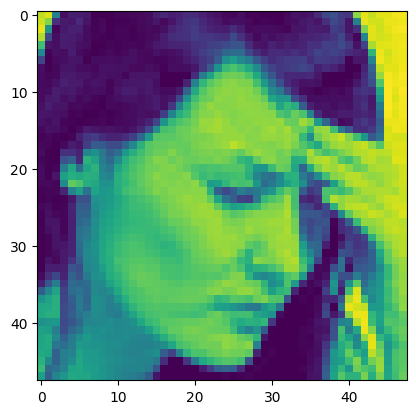

In [8]:
import matplotlib.pyplot as plt
plt.imshow(images[2].numpy().astype("uint8"))
plt.show()

### XÂY MODEL

In [48]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

In [49]:
inputs = tf.keras.Input(
    shape=(96, 96, 3)
)

# Preprocessing dành cho MobileNetV2
x = tf.keras.applications.mobilenet_v2.preprocess_input(
    inputs
)

# Backbone
x = base_model(
    x,
    training=False
)

# Chuyển feature map thành vector
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Fully connected layer
x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(x)

# Giảm overfitting
x = tf.keras.layers.Dropout(0.5)(x)

# 7 emotions
outputs = tf.keras.layers.Dense(
    7,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs
)

## KIểm tra model

In [50]:
model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,855 (9.24 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [51]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [53]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# Model checkpoint để lưu model tốt nhất
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    "best_emotion_model.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

## TRAIN MÔ HÌNH

In [54]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop, reduce_lr, checkpoint_cb]
)

Epoch 1/40


C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


    449/Unknown 65s 136ms/step - accuracy: 0.2831 - loss: 1.8197

C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_accuracy improved from None to 0.32335, saving model to best_emotion_model.keras

Epoch 1: finished saving model to best_emotion_model.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 81s 171ms/step - accuracy: 0.2831 - loss: 1.8197 - val_accuracy: 0.3233 - val_loss: 1.6853 - learning_rate: 1.0000e-04
Epoch 2/40
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.3374 - loss: 1.6584
Epoch 2: val_accuracy improved from 0.32335 to 0.35706, saving model to best_emotion_model.keras

Epoch 2: finished saving model to best_emotion_model.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 66s 146ms/step - accuracy: 0.3374 - loss: 1.6584 - val_accuracy: 0.3571 - val_loss: 1.6349 - learning_rate: 1.0000e-04
Epoch 3/40
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.3695 - loss: 1.6069
Epoch 3: val_accuracy improved from 0.35706 to 0.37448, saving model to best_emotion_model.keras

Epoch 3: finished saving model to best_emotion_model.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 58s 129ms/step - accuracy: 0.3

KeyboardInterrupt: 

In [1]:
import tensorflow as tf

model = tf.keras.models.load_model("best_finetuned_model.keras")
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,125,911 (23.37 MB)

 Trainable params: 1,848,967 (7.05 MB)

 Non-trainable params: 579,008 (2.21 MB)

 Optimizer params: 3,697,936 (14.11 MB)